# pyATM: the TelCal WVR, Atmosphere and Sideband-ratio calibrations

This notebook reproduces, step by step, how the TelCal engines in `TELCAL/TelCalResults/Engines/src`
use ATM:

* **WVR calibration** (`WVRScan.cpp`): 183 GHz radiometer grid, sky-coupling fit, water vapour retrieval
  and the path-length coefficients.
* **Atmosphere calibration** (`AtmosphereScan.cpp`): double-sideband sky temperatures, opacities and Tsys.
* **Sideband ratio** (`SideBandRatioScan.cpp`): signal/image opacities used to correct the sideband gain ratio.

No ASDM is needed: the inputs (weather, frequencies, radiometer temperatures) are made up, the
ATM calls and the formulas are the ones of the engines.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyatm import (Angle, AtmProfile, DSB, Frequency, Humidity, LSB, Length, Percent, Pressure,
                   RefractiveIndexProfile, SkyStatus, SpectralGrid, Temperature, USB, WVRMeasurement,
                   WaterVaporRadiometer)

H_DIV_K = 6.62607015e-34 / 1.380649e-23   # h/k [K/Hz]
T_CMB = 2.725                             # cosmic background temperature [K]

## Atmospheric profile from the weather station

All three engines build the profile in the same way (e.g. `WVRScan.cpp` and `SideBandRatioScan.cpp`):
tropical atmosphere, 5 mb primary pressure step, 1.075 step factor and a 48 km top.

In [2]:
# Weather station values (made up, typical of the ALMA AOS)
altitude, pressure_pa, ground_temp, humidity = 5058.7, 55500.0, 270.0, 15.0
lapse_rate, water_scale_height = 5.6, 2000.0     # K/km, m

profile = AtmProfile(Length(altitude, "m"), Pressure(pressure_pa, "Pa"), Temperature(ground_temp, "K"),
                     -lapse_rate, Humidity(humidity, "%"), Length(water_scale_height, "m"),
                     Pressure(5, "mb"), 1.075, Length(48.0, "km"), 1)
print(f"{profile.getAtmosphereType()}: {profile.getNumLayer()} layers, "
      f"first guess PWV {profile.getGroundWH2O().get('mm'):.3f} mm")

TROPICAL: 35 layers, first guess PWV 1.184 mm


## 1. WVR calibration (`WVRScan`)

### 1.1 Spectral grid: `WVRScan::initSpectralGrid`

Each of the four WVR channels becomes a DSB pair of spectral windows (11 channels). The grid is always
defined from the LSB side, so a channel above the LO is mirrored. The astronomical band(s) are appended
as single-channel windows.

In [3]:
def init_wvr_spectral_grid(chan_freq, chan_width, freq_lo, num_astro_spw, freq_start_astro, bandwidth_astro):
    numchan, refchan = 11, 11 // 2
    wvr_signal_id = []
    grid = None
    for i, (cf, cw) in enumerate(zip(chan_freq, chan_width)):
        if cf > freq_lo:
            ref_freq, int_freq = cf - 2 * (cf - freq_lo), cf - freq_lo   # centre of the LSB band
        else:
            ref_freq, int_freq = cf, freq_lo - cf
        if grid is None:
            wvr_signal_id.append(0)
            grid = SpectralGrid(numchan, refchan, Frequency(ref_freq), Frequency(cw / (numchan - 1)),
                                Frequency(int_freq), LSB, DSB)
        else:
            wvr_signal_id.append(grid.getNumSpectralWindow())
            # NB: WVRScan uses chanWidth/numchan for the channels after the first one
            grid.add(numchan, refchan, Frequency(ref_freq), Frequency(cw / numchan), Frequency(int_freq), LSB, DSB)
    # NB: as in WVRScan, refChan=1 is used for the single-channel astro band(s). Since ICT-9490 refChan is
    # 0-based, so the channel ends up one bandwidth below freqStart + bandwidth/2 (see the printout below).
    if num_astro_spw == 1:
        grid.add(1, 1, Frequency(freq_start_astro + bandwidth_astro / 2), Frequency(bandwidth_astro))
    else:
        width = 1e8
        interval = (bandwidth_astro - width) / (num_astro_spw - 1)
        for i in range(num_astro_spw):
            grid.add(1, 1, Frequency(freq_start_astro + width / 2 + (i - 1) * interval), Frequency(width))
    return grid, wvr_signal_id


freq_lo = 183.31e9
chan_freq = [freq_lo + d for d in (1.25e9, 3.25e9, 5.5e9, 7.25e9)]   # sky frequencies of the USB side
chan_width = [0.16e9, 0.75e9, 1.25e9, 1.50e9]
num_astro_spw = 1
grid, wvr_signal_id = init_wvr_spectral_grid(chan_freq, chan_width, freq_lo, num_astro_spw, 230e9, 2e9)

for j in range(grid.getNumSpectralWindow()):
    print(f"spw {j}: centre {grid.getChanFreq(j, grid.getNumChan(j) // 2).get('GHz'):8.3f} GHz, "
          f"resolution {grid.getChanSep(j).get('MHz'):7.2f} MHz, LO {grid.getLoFrequency(j) / 1e9:7.2f} GHz, "
          f"{grid.getNumChan(j)} channels")
print("WVR signal spws:", wvr_signal_id)

spw 0: centre  182.060 GHz, resolution   16.00 MHz, LO  183.31 GHz, 11 channels
spw 1: centre  184.560 GHz, resolution  -16.00 MHz, LO  183.31 GHz, 11 channels
spw 2: centre  180.060 GHz, resolution   68.18 MHz, LO  183.31 GHz, 11 channels
spw 3: centre  186.560 GHz, resolution  -68.18 MHz, LO  183.31 GHz, 11 channels
spw 4: centre  177.810 GHz, resolution  113.64 MHz, LO  183.31 GHz, 11 channels
spw 5: centre  188.810 GHz, resolution -113.64 MHz, LO  183.31 GHz, 11 channels
spw 6: centre  176.060 GHz, resolution  136.36 MHz, LO  183.31 GHz, 11 channels
spw 7: centre  190.560 GHz, resolution -136.36 MHz, LO  183.31 GHz, 11 channels
spw 8: centre  229.000 GHz, resolution 2000.00 MHz, LO  231.00 GHz, 1 channels
WVR signal spws: [0, 2, 4, 6]


### 1.2 Sky coupling fit and water vapour retrieval

`RefractiveIndexProfile` + `SkyStatus`, then a `WaterVaporRadiometer` with the first-guess sky coupling,
50% signal gain and the spill-over temperature. When the data cover enough air mass
(`max - min > 0.1`), `updateSkyCoupling_fromWVR` fits the sky coupling; `WaterVaporRetrieval_fromWVR`
then retrieves the water column from the averaged measurement.

Here the "measurements" are simulated with a true sky coupling of 0.97 and 0.85 mm of water,
while the engine starts from a coupling of 0.90.

In [4]:
abs_profile = RefractiveIndexProfile(grid, profile)
sky = SkyStatus(abs_profile)

true_pwv, true_coupling, tspill = Length(0.85, "mm"), 0.97, Temperature(275.0, "K")

def simulate(elevation_deg):
    am = 1 / np.sin(np.radians(elevation_deg))
    return WVRMeasurement(Angle(elevation_deg, "deg"),
                          [sky.getAverageTebbSky(i, true_pwv, am, true_coupling, 0.5, tspill) for i in wvr_signal_id])

wvr_data = [simulate(el) for el in np.arange(25.0, 85.0, 5.0)]     # e.g. a sky dip
average_wvr_data = [simulate(60.0)]                                 # the averaged on-source data

airmass = 1 / np.sin(average_wvr_data[0].getElevation().get("rad"))
sky.setAirMass(airmass)
sky.setUserWH2O(profile.getGroundWH2O())

sky_coupling_1st_guess = 0.90
wvr180ghz = WaterVaporRadiometer(wvr_signal_id, [sky_coupling_1st_guess] * len(wvr_signal_id),
                                 [Percent(50.0, "%")] * len(wvr_signal_id), tspill)
sky.setWaterVaporRadiometer(wvr180ghz)

airmasses = [m.getAirMass() for m in wvr_data]
if max(airmasses) - min(airmasses) > 0.1:
    sky.updateSkyCoupling_fromWVR(wvr_data, 0, len(wvr_data))
print("Fitted sky couplings:", [round(sky.getWaterVaporRadiometerSkyCoupling(i), 4) for i in range(4)])

sky.WaterVaporRetrieval_fromWVR(average_wvr_data, 0, 1)
print(f"Retrieved PWV {sky.getUserWH2O().get('mm'):.4f} mm (true {true_pwv.get('mm')} mm), "
      f"fit sigma {average_wvr_data[0].getSigmaFit().get('K'):.3e} K")

Fitted sky couplings: [0.9675, 0.9675, 0.9675, 0.9675]
Retrieved PWV 0.8448 mm (true 0.85 mm), fit sigma 4.035e-01 K


### 1.3 Path-length coefficients

For every WVR channel the engine computes $\partial T_{ebb}/\partial w$ with a 1 µm step (average of
the LSB and USB windows), and for every astronomical band the non-dispersive path per unit of water.
The phase-correction coefficients are weighted ratios of the two; the wet and dry paths along the
line of sight are also reported.

In [5]:
num_chan_wvr = len(wvr_signal_id)
w = sky.getUserWH2O().get("mm")
wvr_dpath = []     # dh2o/dTebb [micron/K]
for ilsb in wvr_signal_id:
    iusb = ilsb + 1
    d_lsb = sky.getAverageTebbSky(ilsb, Length(w + 0.001, "mm")).get("K") - sky.getAverageTebbSky(ilsb).get("K")
    d_usb = sky.getAverageTebbSky(iusb, Length(w + 0.001, "mm")).get("K") - sky.getAverageTebbSky(iusb).get("K")
    wvr_dpath.append(2.0 / (d_lsb + d_usb))

first_astro_spw = sky.getNumSpectralWindow() - num_astro_spw
dpath_vs_dh2o, freq_astro, wet_path, dry_path = [], [], [], []
for isw in range(num_astro_spw):
    astro_band = first_astro_spw + isw
    dpath_vs_dh2o.append(sky.getAverageNonDispersiveH2OPathLength(astro_band).get("microns")
                         / sky.getUserWH2O().get("microns"))
    freq_astro.append(sky.getChanFreq(astro_band, grid.getNumChan(astro_band) // 2).get("GHz"))
    wet_path.append(sky.getAverageNonDispersiveH2OPathLength(astro_band).get() * airmass)
    dry_path.append(sky.getAverageNonDispersiveDryPathLength(astro_band).get() * airmass)

coeff = np.zeros((num_chan_wvr, num_astro_spw))
for isw in range(num_astro_spw):
    sumweight = sum(1.0 / (d * d) for d in wvr_dpath)
    for i in range(num_chan_wvr):
        coeff[i, isw] = dpath_vs_dh2o[isw] / wvr_dpath[i] / sumweight

for i in range(num_chan_wvr):
    print(f"WVR channel {i}: dh2o/dTebb = {wvr_dpath[i]:8.3f} micron/K, "
          f"path coefficient = {coeff[i, 0]:.4f} micron/K")
print(f"Astro band {freq_astro[0]:.1f} GHz: dpath/dh2o = {dpath_vs_dh2o[0]:.3f}, "
      f"wet path = {wet_path[0] * 1e3:.3f} mm, dry path = {dry_path[0] * 1e3:.1f} mm")

WVR channel 0: dh2o/dTebb =    9.030 micron/K, path coefficient = 37.4709 micron/K
WVR channel 1: dh2o/dTebb =   12.973 micron/K, path coefficient = 26.0810 micron/K
WVR channel 2: dh2o/dTebb =   24.187 micron/K, path coefficient = 13.9888 micron/K
WVR channel 3: dh2o/dTebb =   34.931 micron/K, path coefficient = 9.6862 micron/K
Astro band 229.0 GHz: dpath/dh2o = 7.016, wet path = 6.843 mm, dry path = 1540.2 mm


## 2. Atmosphere calibration (`AtmosphereScan`)

### 2.1 Spectral grid: `AtmosphereScan::initSpectralGrid`

One DSB `SpectralGrid` per baseband. Each spectral window is defined by its first channel
(`refChan = 0`, `refFreq = chanFreqStart`), the IF `|LO1 - refFreq|` and the side of the LO.

In [6]:
freq_lo1 = 230.0e9
basebands = {  # baseband -> list of (chanFreqStart, chanFreqStep, numChan)
    1: [(232.0e9, 15.625e6, 128)],
    2: [(234.0e9, 15.625e6, 128)],
    3: [(226.0e9, -15.625e6, 128)],
}
sp_grids = []
for bb, spws in basebands.items():
    g = None
    for ref_freq, step, nchan in spws:
        side = USB if ref_freq > freq_lo1 else LSB
        args = (nchan, 0, Frequency(ref_freq), Frequency(step), Frequency(abs(freq_lo1 - ref_freq)), side, DSB)
        if g is None:
            g = SpectralGrid(*args)
        else:
            g.add(*args)
    sp_grids.append(g)
for bb, g in zip(basebands, sp_grids):
    print(f"BB{bb}: signal {g.getMinFreq(0).get('GHz'):.3f}-{g.getMaxFreq(0).get('GHz'):.3f} GHz ({g.getSidebandSide(0)}), "
          f"image {g.getMinFreq(1).get('GHz'):.3f}-{g.getMaxFreq(1).get('GHz'):.3f} GHz ({g.getSidebandSide(1)})")

BB1: signal 232.000-233.984 GHz (USB), image 226.016-228.000 GHz (LSB)
BB2: signal 234.000-235.984 GHz (USB), image 224.016-226.000 GHz (LSB)
BB3: signal 224.016-226.000 GHz (LSB), image 234.000-235.984 GHz (USB)


### 2.2 Sky temperatures, opacities, $J_{sky}$ and $T_{sys}$

For every baseband: `RefractiveIndexProfile` and `SkyStatus` with the air mass and the water column
(from the WVR). Per channel and sideband ($s$ = signal, image):

$$\tau_s = (\tau_{wet} + \tau_{dry})\, A, \qquad J_{bg} = \frac{T_0}{e^{T_0/T_{CMB}} - 1},
\qquad J_{atm} = \frac{T_{RJ} - J_{bg} e^{-\tau}}{1 - e^{-\tau}}$$

$$J_{sky} = \sum_s g_s \left[\eta_f T_{RJ,s} + (1-\eta_f) J(T_{spill})\right],
\qquad T_{sys,s} = \frac{e^{\tau_s}}{g_s\, \eta_f} (T_{rec} + J_{sky})$$

with $T_0 = h\nu/k$, $g_{signal} = g$, $g_{image} = 1-g$. In the engine $T_{rec}$ comes from the
hot/ambient load measurements; here a constant value is assumed.

BB1: <Tebb_sig>=23.89 K  <Trj_sig>=18.74 K  <tau_sig>=0.0782  <tau_img>=0.0669  <Jatm>=248.05 K  <Jsky>=23.45 K  <Tsys>=89.1 K
BB2: <Tebb_sig>=26.36 K  <Trj_sig>=21.14 K  <tau_sig>=0.0904  <tau_img>=0.0648  <Jatm>=245.01 K  <Jsky>=25.54 K  <Tsys>=93.0 K


BB3: <Tebb_sig>=20.87 K  <Trj_sig>=15.94 K  <tau_sig>=0.0648  <tau_img>=0.0904  <Jatm>=251.16 K  <Jsky>=21.37 K  <Tsys>=85.4 K


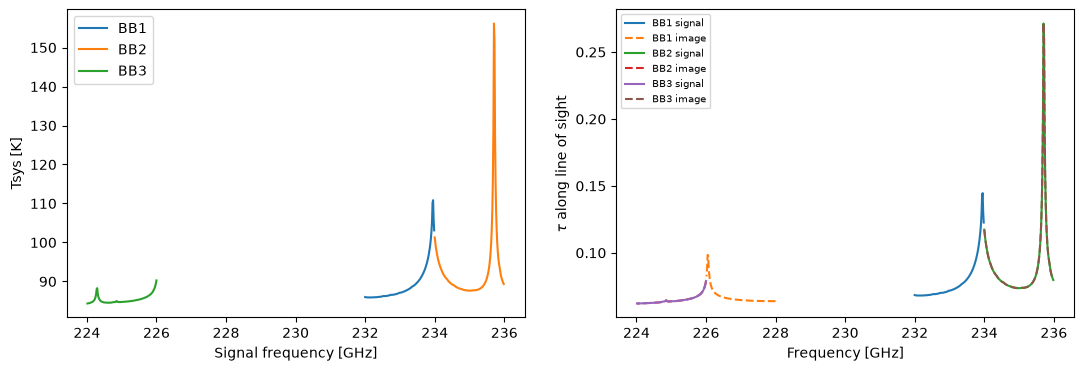

In [7]:
elevation, water = 45.0, sky.getUserWH2O()       # water from the WVR retrieval above
airmass_atm = 1 / np.sin(np.radians(elevation))
etaf, tsp = 0.98, ground_temp                     # DEFAULT_SKYCOUPLING, spill-over = ground temperature
g, trec = 0.91, 50.0                              # signal sideband gain fraction, receiver temperature [K]
SIGNAL, IMAGE = 0, 1
gb = (g, 1 - g)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for bb, grid_bb in zip(basebands, sp_grids):
    sky_bb = SkyStatus(RefractiveIndexProfile(grid_bb, profile))
    sky_bb.setAirMass(airmass_atm)
    sky_bb.setUserWH2O(water)
    spw_id = 0
    nchan = grid_bb.getNumChan(spw_id)
    tebb = np.array([[sky_bb.getTebbSky(spw_id + s, ich).get() for ich in range(nchan)] for s in (SIGNAL, IMAGE)])
    trj = np.array([[sky_bb.getTrjSky(spw_id + s, ich).get() for ich in range(nchan)] for s in (SIGNAL, IMAGE)])
    tau = np.array([[(sky_bb.getWetOpacity(spw_id + s, ich).get() + sky_bb.getDryOpacity(spw_id + s, ich).get())
                     * airmass_atm for ich in range(nchan)] for s in (SIGNAL, IMAGE)])
    nu = np.array([[sky_bb.getChanFreq(spw_id + s, ich).get() for ich in range(nchan)] for s in (SIGNAL, IMAGE)])
    t0 = nu * H_DIV_K
    jbg = t0 / (np.exp(t0 / T_CMB) - 1)
    jsp = t0 / (np.exp(t0 / tsp) - 1)
    jatm = (trj - jbg * np.exp(-tau)) / (1 - np.exp(-tau))
    jsky = sum(gb[s] * (etaf * trj[s] + (1 - etaf) * jsp[s]) for s in (SIGNAL, IMAGE))
    tsys = np.exp(tau[SIGNAL]) / gb[SIGNAL] / etaf * (trec + jsky)
    print(f"BB{bb}: <Tebb_sig>={sky_bb.getAverageTebbSky(spw_id).get():.2f} K  "
          f"<Trj_sig>={sky_bb.getAverageTrjSky(spw_id).get():.2f} K  "
          f"<tau_sig>={tau[SIGNAL].mean():.4f}  <tau_img>={tau[IMAGE].mean():.4f}  "
          f"<Jatm>={jatm[SIGNAL].mean():.2f} K  <Jsky>={jsky.mean():.2f} K  <Tsys>={tsys.mean():.1f} K")
    ax[0].plot(nu[SIGNAL] / 1e9, tsys, label=f"BB{bb}")
    ax[1].plot(nu[SIGNAL] / 1e9, tau[SIGNAL], label=f"BB{bb} signal")
    ax[1].plot(nu[IMAGE] / 1e9, tau[IMAGE], "--", label=f"BB{bb} image")
ax[0].set_xlabel("Signal frequency [GHz]"); ax[0].set_ylabel("Tsys [K]"); ax[0].legend()
ax[1].set_xlabel("Frequency [GHz]"); ax[1].set_ylabel(r"$\tau$ along line of sight"); ax[1].legend(fontsize=7)
plt.show()

## 3. Sideband ratio (`SideBandRatioScan`)

Same profile and DSB grid (11 channels per window when the data are channel-averaged). The signal and
image opacities along the line of sight correct the measured image/signal ratio:

$$g = \left[1 + \left(\frac{I}{S}\, \frac{F_S}{F_I}\, \frac{\eta_S}{\eta_I}\, e^{\tau_I - \tau_S}\right)^{-1}\right]^{-1}
\quad\Rightarrow\quad g_{signal} = 1 - g$$

In [8]:
sbr_grid = SpectralGrid(11, 5, Frequency(345.8e9), Frequency(0.2e9), Frequency(6.0e9), USB, DSB)  # Band 7
sbr_sky = SkyStatus(RefractiveIndexProfile(sbr_grid, profile))
sbr_sky.setAirMass(airmass_atm)
sbr_sky.setUserWH2O(water)

tau = [[(sbr_sky.getWetOpacity(spw, ich).get() + sbr_sky.getDryOpacity(spw, ich).get()) * airmass_atm
        for ich in range(sbr_grid.getNumChan(spw))] for spw in (0, 1)]


def signal_gain(sig, img, tau_sig, tau_img, flux_ratio=1.0, ant_eff_ratio=1.0):
    g = (img / sig) * flux_ratio * ant_eff_ratio * np.exp(tau_img - tau_sig)   # image/signal
    g = 1 / (1 + 1 / g)
    return 1.0 - g                                                             # signal/(signal+image)


measured_ratio = 0.10   # image/signal amplitude ratio measured on the calibrator
ich = 5
print(f"signal {sbr_grid.getChanFreq(0, ich).get('GHz'):.2f} GHz tau={tau[0][ich]:.4f}, "
      f"image {sbr_grid.getChanFreq(1, ich).get('GHz'):.2f} GHz tau={tau[1][ich]:.4f}")
print(f"signal gain fraction without opacity correction: {signal_gain(1.0, measured_ratio, 0.0, 0.0):.4f}")
print(f"signal gain fraction with opacity correction:    {signal_gain(1.0, measured_ratio, tau[0][ich], tau[1][ich]):.4f}")

signal 345.80 GHz tau=0.2083, image 333.80 GHz tau=0.2308
signal gain fraction without opacity correction: 0.9091
signal gain fraction with opacity correction:    0.9072
